# Decision Tree Model

CRISP-DM phase: Modelling + Evaluation

This notebook trains a decision tree to predict whether a Kenyan county will have a recorded flood next month (`flood_next_month`), using the 24 features prepared in the preprocessing notebook plus `flood_this_month` (whether the county flooded this month).

## 1. Setup and Data Loading

### 1.1 Importing Libraries

In [1]:
import os
import json
import joblib
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import GroupKFold, RandomizedSearchCV, cross_val_predict, cross_validate
from sklearn.metrics import classification_report, confusion_matrix, recall_score, precision_score, f1_score, roc_auc_score, average_precision_score, precision_recall_curve

### 1.2 Loading the Training and Test Sets

In [2]:
#loading the saved training and test sets (pcode as text)
train = pd.read_csv('../data/train.csv', dtype={'pcode': str})
test = pd.read_csv('../data/test.csv', dtype={'pcode': str})

### 1.3 Features and Target

We predict at the end of month t whether a county floods in month t+1. `flood_this_month` says whether it flooded in month t, which is already known at that moment, so it is a lag of the target, like `rain_lag1`, and it is used as a feature (notebook 01, Section 4.3, checks that it is a clean lag). It also stays in `train` and `test` because it is the persistence baseline in Section 8. Two limits: it assumes this month's floods are known by the end of the month, and many floods last several months, so the tree may partly "predict" floods that are already happening. Section 7 therefore scores new floods and continuing floods separately.

In [3]:
#columns that are not features: keys and target (flood_this_month stays a feature and is also the persistence baseline)
not_features = ['pcode', 'county', 'year', 'month', 'flood_next_month']

In [4]:
#separating the features (X) from the target (y)
X_train = train.drop(not_features, axis=1)
y_train = train['flood_next_month']
X_test = test.drop(not_features, axis=1)
y_test = test['flood_next_month']

In [5]:
#shapes and number of floods in each set
print(X_train.shape, y_train.sum())
print(X_test.shape, y_test.sum())

(9870, 25) 882
(2820, 25) 144


In [6]:
#the list of features
print(X_train.columns.tolist())

['flood_this_month', 'rain_mm', 'rain_lag1', 'rain_lag2', 'rain_pct_normal', 'neighbour_rain', 'ndvi_pct_normal', 'oni', 'dmi', 'month_sin', 'month_cos', 'soil_moisture_l1', 'runoff_rank', 'discharge_rank', 'pct_flat', 'area_km2', 'lc_tree', 'lc_grass', 'lc_crop', 'lc_bare', 'pct_within_1km_river', 'pct_water', 'pct_occasional_water', 'pop_density', 'county_flood_rate']


In [7]:
#share of flood rows in each set
print(round(y_train.mean(), 3), round(y_test.mean(), 3))

0.089 0.051


#### Observation

The training set has 9,870 rows with 882 floods (share 0.089) and the test set has 2,820 rows with 144 floods (share 0.051). Both have 25 features: the 24 features of the preprocessing notebook plus `flood_this_month`, which is the first column. The 4 keys and the target are not features. `flood_this_month` is still a column of `train` and `test`, so the persistence baseline can use it. The share of floods is also the PR-AUC of a model with no skill: 0.089 in training and 0.051 in the test set.

## 2. Cross-Validation and How the Settings Are Chosen

All the choices in this notebook (the settings of the tree and the probability threshold) are made with 5-fold cross-validation on the training set only. The test set is used once, at the end, and nothing is changed after it.

The folds keep **whole years together** (`GroupKFold` with the year as the group). The counties in the same month share the same weather: `oni` and `dmi` have the same value for every county, and floods often hit many counties at once. If one county's October 2015 is in the training part and another county's October 2015 is in the validation part, the tree can learn "October 2015 was a flood month" and the scores look better than they really are. With whole years held out, each fold is tested on years the tree has not seen at all. The same folds are used in all the model notebooks.

In [8]:
#5-fold cross-validation that keeps whole years together
year_cv = GroupKFold(n_splits=5)

In [9]:
#years, rows and floods in the validation part of each fold
for fold, (train_idx, val_idx) in enumerate(year_cv.split(X_train, y_train, groups=train['year']), start=1):
    val_rows = train.iloc[val_idx]
    print('fold', fold, 'years', val_rows['year'].unique(), 'rows', len(val_rows), 'floods', val_rows['flood_next_month'].sum(), 'flood rate', round(val_rows['flood_next_month'].mean(), 3))

fold 1 years [2004 2009 2014 2019] rows 2256 floods 128 flood rate 0.057
fold 2 years [2003 2008 2013 2018] rows 2256 floods 175 flood rate 0.078
fold 3 years [2002 2007 2012 2017] rows 1974 floods 211 flood rate 0.107
fold 4 years [2006 2011 2016] rows 1692 floods 174 flood rate 0.103
fold 5 years [2005 2010 2015] rows 1692 floods 194 flood rate 0.115


#### Observation

Each fold holds out whole years: three or four years spread across the period (for example 2004, 2009, 2014 and 2019), so every fold has early, middle and late years. Folds 1 and 2 have 2,256 rows (four full years), folds 4 and 5 have 1,692 rows (three full years), and fold 3 has 1,974 rows because it holds 2002, which only has six months. Together the folds cover all 9,870 rows and all 882 floods once. The flood rate changes from 0.057 in fold 1 (128 floods) to 0.115 in fold 5 (194 floods). Because the folds are not balanced on floods, the scores are expected to change from fold to fold.

### 2.1 How the Settings Are Chosen

The work is done in two jobs.

**Job 1: choose the settings by PR-AUC.** PR-AUC (average precision) looks at all the possible probability cuts at once. It is high when the months that flood get higher probabilities than the months that do not, so it measures how well the model ranks the months. It does not go up just because a model warns more often. A model with no skill scores the share of floods (0.089 in the training set, see Section 1.3). `RandomizedSearchCV` tries 80 combinations of the settings, scores each one with PR-AUC in the 5 year folds and keeps the combination with the highest mean. All the settings are searched together, so a setting is judged together with the others and not alone, and the class weight is one of the settings searched. The values to try are given as plain lists, and `random_state=42` makes the search repeatable.

**Job 2: choose the threshold for 80% recall.** The model gives each month a flood probability, and the threshold decides from which probability on we raise a warning. Recall is still the main goal, because a missed flood is the most dangerous mistake: a county is not warned and lives can be lost. But recall is set by the threshold, not by weakening the model. We take the out-of-fold probabilities (each training row is predicted by a model that did not see its year) and pick the highest threshold where the out-of-fold recall is at least 0.80. The threshold comes from cross-validation only, never from the test set. Precision and the share of months flagged are shown next to recall, because false alarms waste money and staff time and make people stop trusting the warnings. We also checked the threshold with the highest F1 (Section 6.5). 80% recall was chosen because a missed flood is the most dangerous mistake.

**Limits that stay:** `GroupKFold` trains on years both before and after the held-out years, so it is not a pure forecast of the future, and `county_flood_rate` is calculated from all the training years, so the cross-validation scores are slightly optimistic.

## 3. Base Model

The decision tree is first trained with all default settings. It is judged with the PR-AUC and the ROC-AUC of the year folds from Section 2. This is the starting point that the search in Section 4 has to beat. With the default settings the tree has no limit on its depth and no class weights.

In [10]:
#base model with all default settings
model_default = DecisionTreeClassifier(random_state=42)

In [11]:
#pr-auc and roc-auc in each fold for the default model
scores_default = cross_validate(model_default, X_train, y_train, cv=year_cv, groups=train['year'], scoring=['average_precision', 'roc_auc'])
print(scores_default['test_average_precision'].round(3))
print(scores_default['test_average_precision'].mean().round(3), scores_default['test_average_precision'].std().round(3))
print(scores_default['test_roc_auc'].mean().round(3), scores_default['test_roc_auc'].std().round(3))

[0.099 0.124 0.125 0.202 0.213]
0.153 0.046
0.619 0.042


#### Observation

The default tree has a mean PR-AUC of 0.153 (std 0.046) and a mean ROC-AUC of 0.619 (std 0.042) in the year folds. A tree with no limits grows until it fits the training rows almost exactly, so on new years it is only a little above 0.089, the score of a model with no skill. This is the score the search has to beat.

## 4. Choosing the Settings with a Randomized Search

The settings searched are:

- `max_depth`: how many questions in a row the tree can ask (`None` means no limit).
- `min_samples_leaf`: the smallest number of training rows a leaf may hold, so a leaf cannot rest on a handful of rows.
- `ccp_alpha`: a penalty for the size of the tree. The tree is first grown and then the branches that add little are cut off. A larger value cuts more (0 cuts nothing).
- `class_weight`: `None` counts every row the same, `'balanced'` counts each flood more than a no-flood month, in proportion to how rare floods are.

The lists hold 8 values of `max_depth`, 8 of `min_samples_leaf`, 4 of `ccp_alpha` and 2 class weights, so there are many possible combinations. The search tries 80 of them.

In [12]:
#the values to try for each setting
param_lists = {'max_depth': [2, 3, 4, 5, 6, 8, 10, None],
               'min_samples_leaf': [1, 10, 25, 50, 100, 130, 200, 300],
               'ccp_alpha': [0, 0.0001, 0.0003, 0.001],
               'class_weight': [None, 'balanced']}

In [13]:
#randomized search scored with pr-auc (average precision) on the year folds
search = RandomizedSearchCV(DecisionTreeClassifier(random_state=42), param_distributions=param_lists, n_iter=80,
                            scoring='average_precision', cv=year_cv, random_state=42, n_jobs=-1)
search.fit(X_train, y_train, groups=train['year'])

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeC...ndom_state=42)
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'ccp_alpha': [0, 0.0001, ...], 'class_weight': [None, 'balanced'], 'max_depth': [2, 3, ...], 'min_samples_leaf': [1, 10, ...]}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",80
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'average_precision'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",GroupKFold(n_...shuffle=False)
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``Ra

In [14]:
#all the combinations tried, in the order of their mean pr-auc (None is written as the word None, because it would show as NaN)
results = pd.DataFrame(search.cv_results_).fillna('None')
top5 = results.sort_values('rank_test_score').head(5)
top5[['param_max_depth', 'param_min_samples_leaf', 'param_ccp_alpha', 'param_class_weight', 'mean_test_score', 'std_test_score']].round(3)

,param_max_depth,param_min_samples_leaf,param_ccp_alpha,param_class_weight,mean_test_score,std_test_score
71,8,130,0.000,balanced,0.398,0.076
47,10,130,0.001,balanced,0.389,0.078
24,None,100,0.000,balanced,0.385,0.093
75,6,130,0.000,balanced,0.384,0.074
30,10,100,0.000,balanced,0.381,0.091


In [15]:
#the best settings and their mean pr-auc in cross-validation
print(search.best_params_)
print(round(search.best_score_, 3), round(results.loc[search.best_index_, 'std_test_score'], 3))

{'min_samples_leaf': 130, 'max_depth': 8, 'class_weight': 'balanced', 'ccp_alpha': 0.0001}
0.398 0.076


#### Observation

The best settings are `max_depth` = 8, `min_samples_leaf` = 130, `ccp_alpha` = 0.0001 (shown as 0.000 in the table because of the rounding) and `class_weight` = `'balanced'`, with a mean PR-AUC of 0.398 (std 0.076). That is much higher than the 0.153 of the default tree. All five of the best settings use `'balanced'` and a large `min_samples_leaf` (100 or 130), so every leaf rests on at least 100 training rows. The top 5 range from 0.381 to 0.398, a gap smaller than the std of 0.076 between the folds, so these settings are about equally good.

## 5. Overfitting Gap

The overfitting gap is the PR-AUC on the training rows minus the PR-AUC in cross-validation (on years the tree has not seen). A large gap means the tree has memorised the training data.

In [16]:
#best model, fitted on the full training set by the search
best_model = search.best_estimator_

In [17]:
#fitting the default model on the full training set
model_default.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

In [18]:
#pr-auc on the training rows and in cross-validation, for the default model and the best model
gap_results = pd.DataFrame({'model': ['default', 'best'],
                            'train pr-auc': [average_precision_score(y_train, model_default.predict_proba(X_train)[:, 1]),
                                             average_precision_score(y_train, best_model.predict_proba(X_train)[:, 1])],
                            'cv pr-auc': [scores_default['test_average_precision'].mean(), search.best_score_]})
gap_results['gap'] = gap_results['train pr-auc'] - gap_results['cv pr-auc']
gap_results.round(3)

,model,train pr-auc,cv pr-auc,gap
0,default,1.000,0.153,0.847
1,best,0.507,0.398,0.109


#### Observation

The default tree has a PR-AUC of 1.000 on the training rows and only 0.153 in cross-validation, a gap of 0.847: it has memorised the training rows and does not do the same on new years. The best model has a train PR-AUC of 0.507 and a cross-validation PR-AUC of 0.398, a gap of 0.109. The search found settings that overfit much less and that score higher in cross-validation. A gap does not go to zero, because the model is always a bit better on rows it has seen.

## 6. Choosing the Threshold for 80% Recall

The settings are fixed, so the next job is the threshold: the flood probability from which on we raise a warning. It is chosen with cross-validation only. The test set is not used here.

### 6.1 Out-of-Fold Probabilities

Each training row gets a flood probability from a model that was fitted on the other folds, so the model has not seen the years of that row.

In [19]:
#out-of-fold flood probabilities of the best model (every row is predicted by a model that did not see its year)
oof_prob = cross_val_predict(best_model, X_train, y_train, cv=year_cv, groups=train['year'], method='predict_proba')[:, 1]

In [20]:
#precision and recall for every possible threshold
precision, recall, thresholds = precision_recall_curve(y_train, oof_prob)

### 6.2 The Threshold for 80% Recall

The recall gets lower when the threshold gets higher. We take the highest threshold where the out-of-fold recall is still at least 0.80, which gives the fewest warnings for that recall.

In [21]:
#choosing the threshold for 80% recall
threshold = thresholds[recall[:-1] >= 0.80].max()
print(threshold)

0.2966504812384944


In [22]:
#out-of-fold warnings at this threshold, and their recall, precision and share of months flagged
oof_pred = (oof_prob >= threshold).astype(int)
print('recall', round(recall_score(y_train, oof_pred), 3))
print('precision', round(precision_score(y_train, oof_pred), 3))
print('share of months flagged', round(oof_pred.mean(), 3))

recall 0.805
precision 0.173
share of months flagged 0.416


### 6.3 Confusion Matrix of the Out-of-Fold Predictions

The same kind of matrix as for the test set (Section 7.3), but for the training rows predicted out-of-fold at the chosen threshold. Each row is the true outcome and each column is the prediction.

In [23]:
#confusion matrix of the out-of-fold predictions at the chosen threshold, and the number of warnings
cm_oof = confusion_matrix(y_train, oof_pred)
print(cm_oof)
print('warnings', oof_pred.sum())

[[5597 3391]
 [ 172  710]]
warnings 4101


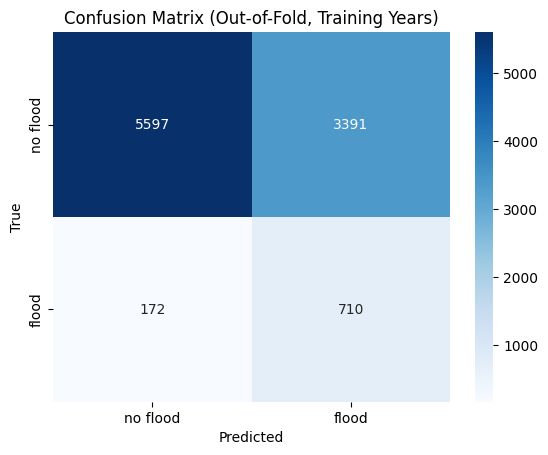

In [24]:
#heatmap of the out-of-fold confusion matrix
sns.heatmap(cm_oof, annot=True, fmt='d', cmap='Blues', xticklabels=['no flood', 'flood'], yticklabels=['no flood', 'flood'])
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix (Out-of-Fold, Training Years)')
plt.show()

#### Observation

In the out-of-fold predictions of the training years (882 floods), the decision tree at the threshold of 0.297 finds 710 floods and misses 172. It gives 4,101 warnings, of which 3,391 are false alarms (a warning in a month with no flood). So there are far more false alarms than floods found, which agrees with the precision of 0.173 in Section 6.2. This is the price of a recall of 0.805: a lower threshold finds more floods and gives more false alarms, a higher one gives fewer false alarms and misses more floods (Section 6.4).

### 6.4 Other Recall Targets

The same steps for recall targets of 0.70 and 0.90, so the trade-off between recall and false alarms is visible.

In [25]:
#threshold, recall, precision and share of months flagged for three recall targets
targets = [0.70, 0.80, 0.90]
cut_list = []
recall_list = []
precision_list = []
flagged_list = []
for target in targets:
    cut = thresholds[recall[:-1] >= target].max()
    pred = (oof_prob >= cut).astype(int)
    cut_list.append(cut)
    recall_list.append(recall_score(y_train, pred))
    precision_list.append(precision_score(y_train, pred))
    flagged_list.append(pred.mean())
target_results = pd.DataFrame({'recall target': targets, 'threshold': cut_list, 'oof recall': recall_list,
                               'oof precision': precision_list, 'share of months flagged': flagged_list})
target_results.round(3)

,recall target,threshold,oof recall,oof precision,share of months flagged
0,0.7,0.527,0.703,0.237,0.265
1,0.8,0.297,0.805,0.173,0.416
2,0.9,0.095,0.902,0.132,0.611


### 6.5 The Threshold with the Highest F1 (for comparison)

F1 combines recall and precision. For comparison we also look for the threshold with the highest out-of-fold F1, next to the persistence baseline on the training rows (a flood this month means a flood next month).

In [26]:
#threshold with the highest out-of-fold f1
f1_values = pd.Series(2 * precision[:-1] * recall[:-1] / (precision[:-1] + recall[:-1]))
best_f1_index = f1_values.idxmax()
print('threshold', round(thresholds[best_f1_index], 3))
print('recall', round(recall[best_f1_index], 3), 'precision', round(precision[best_f1_index], 3), 'f1', round(f1_values[best_f1_index], 3))
print('share of months flagged', round((oof_prob >= thresholds[best_f1_index]).mean(), 3))

threshold 0.913
recall 0.345 precision 0.623 f1 0.444
share of months flagged 0.049


In [27]:
#recall, precision and f1 of the persistence baseline on the training rows
print('recall', round(recall_score(y_train, train['flood_this_month']), 3))
print('precision', round(precision_score(y_train, train['flood_this_month']), 3))
print('f1', round(f1_score(y_train, train['flood_this_month']), 3))

recall 0.463
precision 0.463
f1 0.463


#### Observation

With a threshold of 0.297, the out-of-fold recall of the decision tree is 0.805 (the target was 0.80), the precision is 0.173 and the model flags 0.416 of all the training months. The table shows the trade-off: for a recall of 0.70 the threshold is 0.527, the precision is 0.237 and 0.265 of the months are flagged; for a recall of 0.90 the threshold is 0.095, the precision is 0.132 and 0.611 of the months are flagged. Every extra bit of recall costs more false alarms.

The threshold with the highest F1 is 0.913. It gives a recall of only 0.345, a precision of 0.623 and an F1 of 0.444, and flags only 0.049 of the months. The persistence baseline on the training rows has a recall of 0.463, a precision of 0.463 and an F1 of 0.463. So at its best F1 threshold the decision tree is about as good as the simple rule "a flood this month means a flood next month", and it does not catch more floods than that rule. This is why we set the threshold for 80% recall instead: recall is still the main goal, because a missed flood is the most dangerous mistake, and it is set by the threshold and not by weakening the model. The threshold comes from cross-validation only, and the test set was not used.

## 7. Evaluation on the Test Set

### 7.1 Predicting with the Chosen Threshold

The best settings of Section 4 were fitted on the whole training set (July 2002 to December 2019) by the search. The model is scored once on the test set (2020 to 2024), with the threshold of Section 6. A month gets a warning when its flood probability is at least the threshold. No setting is changed after this point.

In [28]:
#final model: the best settings, fitted on the full training set by the search
model = search.best_estimator_

In [29]:
#flood probabilities for the test set, and the warnings at the chosen threshold
y_prob = model.predict_proba(X_test)[:, 1]
y_pred = (y_prob >= threshold).astype(int)

### 7.2 Classification Report

In [30]:
#recall, precision and f1 for each class on the test set
print(classification_report(y_test, y_pred, target_names=['0 no flood', '1 flood']))

              precision    recall  f1-score   support

  0 no flood       0.99      0.57      0.73      2676
     1 flood       0.11      0.94      0.19       144

    accuracy                           0.59      2820
   macro avg       0.55      0.75      0.46      2820
weighted avg       0.95      0.59      0.70      2820



In [31]:
#recall, precision, f1, roc-auc and pr-auc of the test set
test_scores = pd.DataFrame({'recall': [recall_score(y_test, y_pred)],
                            'precision': [precision_score(y_test, y_pred)],
                            'f1': [f1_score(y_test, y_pred)],
                            'roc-auc': [roc_auc_score(y_test, y_prob)],
                            'pr-auc': [average_precision_score(y_test, y_prob)]})
test_scores.round(3)

,recall,precision,f1,roc-auc,pr-auc
0,0.938,0.105,0.189,0.828,0.291


#### Observation

On the test set, the decision tree with the threshold of 0.297 has a recall of 0.938, a precision of 0.105 and an F1 of 0.189. The ROC-AUC is 0.828 and the PR-AUC is 0.291; a model with no skill would score 0.051 in PR-AUC (the share of floods in the test set). The classification report agrees: the flood class has a recall of 0.94 and a precision of 0.11, and the no-flood class has a recall of 0.57. The model gives 1,281 warnings in the 2,820 test months, so most warnings are false alarms.

The test recall is higher than the 0.80 of cross-validation. The threshold was fixed in Section 6 before the test set was used, so this is a result and not a target we tuned. Notebook 05 looks at the test years one by one to see where the difference comes from.

### 7.3 Confusion Matrix

Each row is the true outcome and each column is the prediction, so the numbers on the diagonal are correct predictions.

In [32]:
#confusion matrix of the test set at the chosen threshold, and the number of warnings
cm = confusion_matrix(y_test, y_pred)
print(cm)
print('warnings', y_pred.sum())

[[1530 1146]
 [   9  135]]
warnings 1281


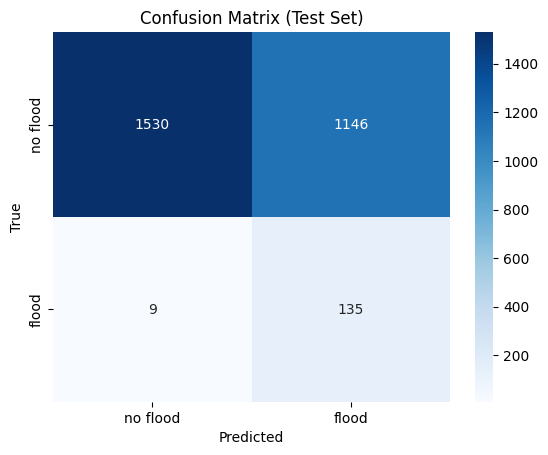

In [33]:
#heatmap of the test confusion matrix
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['no flood', 'flood'], yticklabels=['no flood', 'flood'])
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix (Test Set)')
plt.show()

#### Observation

On the test set (144 floods), the decision tree at the same threshold of 0.297 finds 135 floods and misses 9. It gives 1,281 warnings, of which 1,146 are false alarms. As in cross-validation there are far more false alarms than floods found (precision 0.105). The test recall (0.938) is higher than the out-of-fold recall (0.805), so a smaller share of the floods is missed. The threshold was not changed after the test set was used.

### 7.4 New Floods and Continuing Floods

A **new flood** is a flood next month in a county that did not flood this month (`flood_this_month` is 0). A **continuing flood** is a flood next month in a county that is already flooding this month (`flood_this_month` is 1). Continuing floods are easier to predict, so the two are scored separately.

In [34]:
#floods found among the new floods and among the continuing floods
new_floods = (y_test == 1) & (test['flood_this_month'] == 0)
continuing_floods = (y_test == 1) & (test['flood_this_month'] == 1)
print('new floods', new_floods.sum(), 'found', ((y_pred == 1) & new_floods).sum())
print('continuing floods', continuing_floods.sum(), 'found', ((y_pred == 1) & continuing_floods).sum())

new floods 76 found 67
continuing floods 68 found 68


In [35]:
#warnings in the months where the county is not flooding this month
print('warnings when the county is not flooding this month', ((y_pred == 1) & (test['flood_this_month'] == 0)).sum())
print('warnings when the county is flooding this month', ((y_pred == 1) & (test['flood_this_month'] == 1)).sum())

warnings when the county is not flooding this month 1137
warnings when the county is flooding this month 144


#### Observation

Among the new floods (the county was not flooding this month), the decision tree finds 67 of 76. Among the continuing floods (the county is already flooding this month), it finds 68 of 68. It gives 144 warnings in the months where the county is flooding this month (Section 8 shows that the persistence baseline warns 144 times, once for each of these months), so the continuing floods are found by this rule alone. The new floods are the real test, because the persistence baseline cannot find any of them. The model also gives 1137 warnings in months where the county is not flooding this month, and these are where almost all the false alarms come from.

## 8. Comparison with Two Baselines

A model is only useful if it does better than simple rules that need no model. We compare it with two:

- **Persistence baseline:** predicts a flood next month whenever there is a flood this month (`flood_this_month`). It tests whether the model knows more than the current situation.
- **Calendar baseline:** gives every row the flood rate of its calendar month in the training years, so every March row gets the March rate, whatever the county or the rain. It tests whether the model knows more than the time of year. For a yes/no prediction it flags the months whose flood rate is above the overall training rate.

In [36]:
#persistence baseline predictions on the test set
base_pred = test['flood_this_month']

In [37]:
#flood rate of each calendar month in the training years
month_rate = train.groupby('month')['flood_next_month'].mean()
month_rate.round(3)

month
1     0.016
2     0.090
3     0.183
4     0.185
5     0.054
6     0.020
7     0.046
8     0.044
9     0.069
10    0.131
11    0.134
12    0.102
Name: flood_next_month, dtype: float64

In [38]:
#calendar baseline on the test set: the rate of the month, and yes/no when the rate is above the overall rate
calendar_prob = test['month'].map(month_rate)
calendar_pred = (calendar_prob > y_train.mean()).astype(int)

In [39]:
#months flagged by the calendar baseline and the number of test rows it flags
print(month_rate[month_rate > y_train.mean()].index.tolist())
print(calendar_pred.sum())

[2, 3, 4, 10, 11, 12]
1410


### 8.1 The Three Methods Side by Side

PR-AUC (average precision) does not depend on a probability cut, but it focuses on the flood class: a method with no skill scores the flood share of the test set (0.051). The number of different probabilities the tree gives is checked first: rows with the same probability are tied in the rankings behind ROC-AUC and PR-AUC.

In [40]:
#number of different flood probabilities the model gives on the test set
pd.Series(y_prob).nunique()

33

In [41]:
#recall, precision, f1, roc-auc, pr-auc and warnings for the two baselines and the model
comparison = pd.DataFrame({'method': ['Persistence baseline', 'Calendar baseline', 'Decision tree'],
                           'recall': [recall_score(y_test, base_pred), recall_score(y_test, calendar_pred), recall_score(y_test, y_pred)],
                           'precision': [precision_score(y_test, base_pred), precision_score(y_test, calendar_pred), precision_score(y_test, y_pred)],
                           'f1': [f1_score(y_test, base_pred), f1_score(y_test, calendar_pred), f1_score(y_test, y_pred)],
                           'roc-auc': [roc_auc_score(y_test, base_pred), roc_auc_score(y_test, calendar_prob), roc_auc_score(y_test, y_prob)],
                           'pr-auc': [average_precision_score(y_test, base_pred), average_precision_score(y_test, calendar_prob), average_precision_score(y_test, y_prob)],
                           'warnings': [base_pred.sum(), calendar_pred.sum(), y_pred.sum()]})
comparison.round(3)

,method,recall,precision,f1,roc-auc,pr-auc,warnings
0,Persistence baseline,0.472,0.472,0.472,0.722,0.250,144
1,Calendar baseline,0.847,0.087,0.157,0.762,0.141,1410
2,Decision tree,0.938,0.105,0.189,0.828,0.291,1281


#### Observation

The persistence baseline has a recall of 0.472 and also a precision of 0.472 with 144 warnings. The calendar baseline has a recall of 0.847 but a precision of 0.087 with 1410 warnings. The decision tree has a recall of 0.938 and a precision of 0.105 with 1,281 warnings. It is better than both baselines in ROC-AUC (0.828 against 0.722 and 0.762) and in PR-AUC (0.291 against 0.250 and 0.141), and its recall is higher than both. But persistence has a higher precision (0.472) and a higher F1 (0.472 against 0.189), because it gives far fewer warnings. So the model buys its higher recall with many more warnings, and persistence alone is a strong rule. The ROC-AUC and PR-AUC of the two baselines are calculated from yes/no predictions and not from probabilities, so they are only a rough guide. The tree gives only 33 different probabilities in the test set, so many rows are tied. ROC-AUC and PR-AUC of the tree are therefore step-like and less detailed than those of models that give almost 2,820 different probabilities.

### 8.2 A Fair Recall Comparison

Recall depends on how many warnings a method raises: a method that flags more months will usually find more floods. To compare the tree and the calendar baseline fairly, we let the tree raise as many warnings as the calendar baseline, on the rows it thinks are most likely to flood. This is only a comparison, not a way of choosing the threshold. Rows with exactly the same probability cannot be told apart, so the number of floods found is given as a range.

In [42]:
#number of warnings raised by the calendar baseline and by the model
print(calendar_pred.sum())
print(y_pred.sum())

1410
1281


In [43]:
#ranking the test rows from the highest to the lowest flood probability
test_ranked = test.copy()
test_ranked['prob'] = y_prob
test_ranked = test_ranked.sort_values('prob', ascending=False)

In [44]:
#probability of the last warning if the model raised as many warnings as the calendar baseline
cut_prob = test_ranked['prob'].iloc[calendar_pred.sum() - 1]
print(cut_prob)

0.26875214065532665


In [45]:
#warnings and floods found with a probability above the cut, and with a probability above or equal to the cut
above = test_ranked[test_ranked['prob'] > cut_prob]
print(len(above), above['flood_next_month'].sum())
equal_or_above = test_ranked[test_ranked['prob'] >= cut_prob]
print(len(equal_or_above), equal_or_above['flood_next_month'].sum())

1331 135
1438 135


#### Observation

The calendar baseline gives 1410 warnings and the tree gives 1281. To give 1410 warnings, the tree would need a cut at the probability 0.269, but many rows share this probability: with a probability above the cut it gives 1331 warnings and 135 floods, and with a probability above or equal to the cut it gives 1438 warnings and 135 floods. Either way it finds 135 of the 144 floods, so the tie does not change the number of floods found. The calendar baseline has a recall of 0.847 with its 1410 warnings (table in Section 8.1), so with the same number of warnings the tree finds more floods than the calendar rule.

## 9. Looking Inside the Tree

A decision tree can be read like a flowchart: each box asks a yes/no question about one feature, and the rows go left (yes) or right (no) until they reach a leaf that gives the answer.

### 9.1 Size of the Tree

In [46]:
#depth and number of leaves of the final tree
print(model.get_depth(), model.get_n_leaves())

8 39


### 9.2 The Top of the Tree

In each box, `gini` shows how mixed the rows are (0 means only one class), `samples` is the number of training rows and `value` is the number of no-flood and flood rows (weighted if the class weight is `'balanced'`). Only the first three levels are drawn.

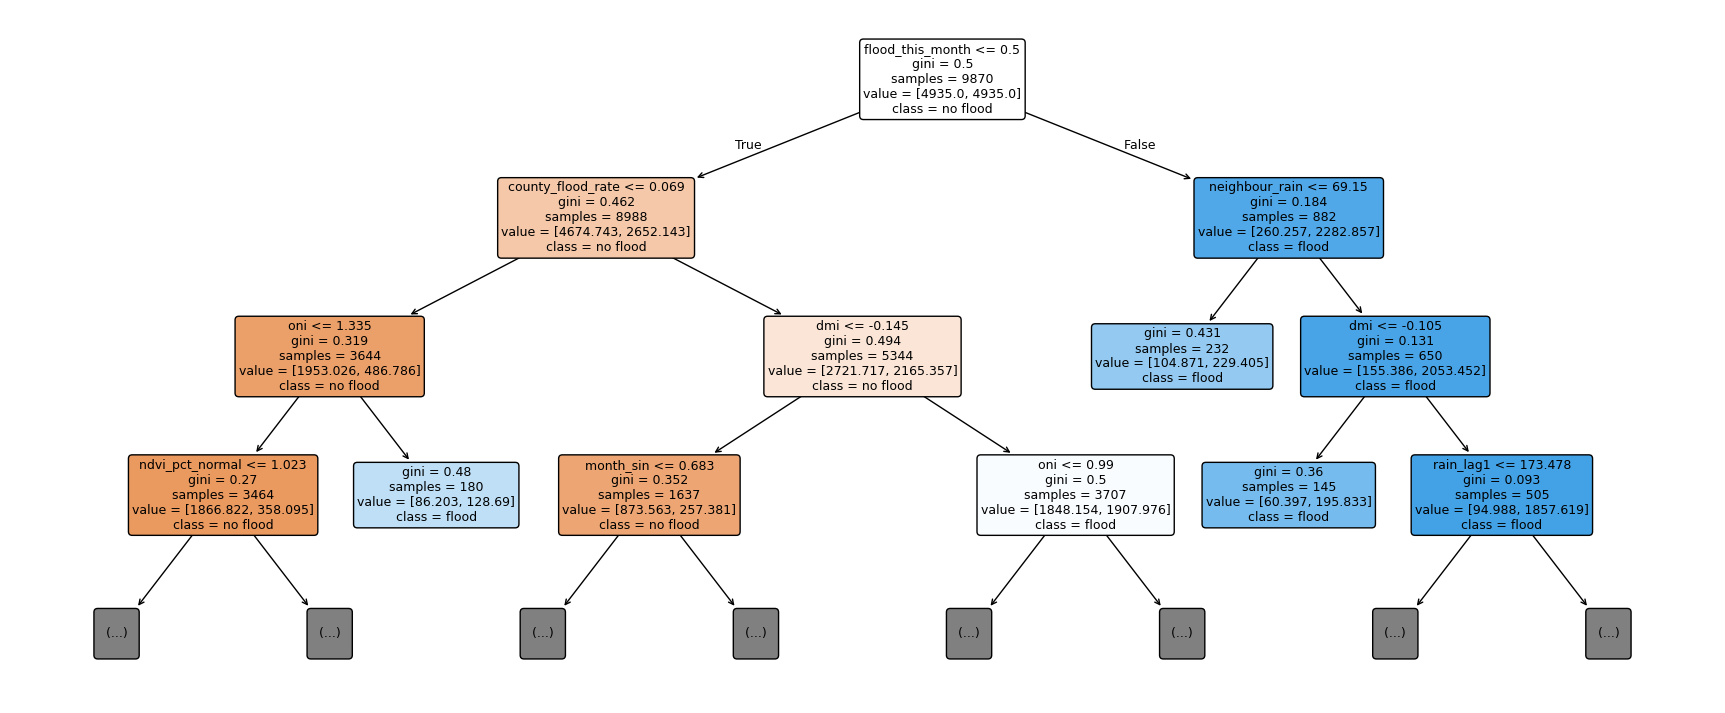

In [47]:
#the first three levels of the final tree
plt.figure(figsize=(22, 9))
plot_tree(model, max_depth=3, feature_names=X_train.columns, class_names=['no flood', 'flood'], filled=True, rounded=True, fontsize=9)
plt.show()

#### Observation

The final tree has a depth of 8 and 39 leaves. Its first question is `flood_this_month <= 0.5`. The 882 training rows with a flood this month go to the right, and every box shown on that side is labelled flood. The 8,988 rows without a flood this month go to the left and are split next by `county_flood_rate` (at 0.069), then by `oni`, `dmi`, `ndvi_pct_normal` and `month_sin`, so the tree uses the climate indices for the months with no flood this month. In every box the numbers in `value` are weighted, because of the balanced class weight: the root shows 4935.0 for each class although it has 9,870 rows.

### 9.3 Feature Importance

The importance of a feature is how much it lowered the gini in all the questions that used it, scaled so that all 25 values add up to 1. It describes this tree only: features the tree never used have an importance of 0, and when two features carry similar information, the tree may use only one of them.

In [48]:
#importance of each feature, from the highest to the lowest
importance = pd.DataFrame({'feature': X_train.columns, 'importance': model.feature_importances_})
importance = importance.sort_values('importance', ascending=False)
importance.round(3)

,feature,importance
0,flood_this_month,0.471
7,oni,0.128
24,county_flood_rate,0.104
8,dmi,0.081
9,month_sin,0.043
10,month_cos,0.039
2,rain_lag1,0.028
1,rain_mm,0.020
5,neighbour_rain,0.018
12,runoff_rank,0.018


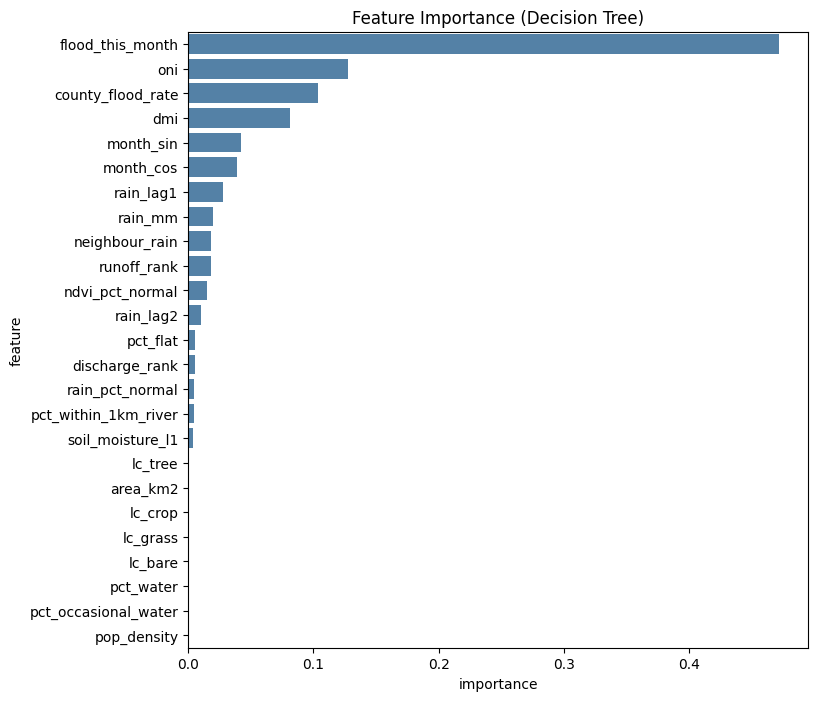

In [49]:
#bar chart of the feature importance
plt.figure(figsize=(8, 8))
sns.barplot(data=importance, x='importance', y='feature', color='steelblue')
plt.title('Feature Importance (Decision Tree)')
plt.show()

#### Observation

`flood_this_month` is by far the most important feature (0.471). Then come `oni` (0.128), `county_flood_rate` (0.104), `dmi` (0.081), `month_sin` (0.043) and `month_cos` (0.039). Eight features show 0.000: the land cover, area, water and population density features, which the tree uses very little or not at all. The tree is small (39 leaves) and every leaf needs many rows, so it keeps only the strongest signals.

## 10. Saving the Model

The final model is saved with `joblib` and its settings and threshold are saved in a `json` file, so that `05_model_comparison.ipynb` can load them instead of copying the settings by hand.

In [50]:
#creating the models folder if it does not exist yet
os.makedirs('../models', exist_ok=True)

In [51]:
#saving the final model
joblib.dump(model, '../models/decision_tree.joblib', compress=3)

['../models/decision_tree.joblib']

In [52]:
#best settings as plain python values so they can be saved in a json file
best_params = {}
for name, value in search.best_params_.items():
    if hasattr(value, 'item'):
        value = value.item()
    best_params[name] = value

In [53]:
#saving the settings, the threshold and the cross-validation scores
settings = {'model': 'Decision tree',
            'best_params': best_params,
            'threshold': float(threshold),
            'recall_target': 0.80,
            'cv_pr_auc_mean': float(search.best_score_),
            'cv_pr_auc_std': float(results.loc[search.best_index_, 'std_test_score']),
            'oof_recall': float(recall_score(y_train, oof_pred)),
            'oof_precision': float(precision_score(y_train, oof_pred)),
            'share_flagged': float(oof_pred.mean())}
with open('../models/decision_tree_settings.json', 'w') as settings_file:
    json.dump(settings, settings_file, indent=2)
print(settings)

{'model': 'Decision tree', 'best_params': {'min_samples_leaf': 130, 'max_depth': 8, 'class_weight': 'balanced', 'ccp_alpha': 0.0001}, 'threshold': 0.2966504812384944, 'recall_target': 0.8, 'cv_pr_auc_mean': 0.39820861699061233, 'cv_pr_auc_std': 0.07604507905891729, 'oof_recall': 0.8049886621315193, 'oof_precision': 0.17312850524262374, 'share_flagged': 0.4155015197568389}


In [54]:
#files in the models folder
print(os.listdir('../models'))

['decision_tree.joblib', 'decision_tree_settings.json', 'logistic_regression.joblib', 'logistic_regression_settings.json', 'random_forest.joblib', 'random_forest_settings.json', 'xgboost.joblib', 'xgboost_settings.json']


## 11. Summary of the Decision Tree Model

- **Method:** Final settings: `DecisionTreeClassifier` with `max_depth` = 8, `min_samples_leaf` = 130, `ccp_alpha` = 0.0001 and `class_weight` = `'balanced'`. The settings were chosen with `RandomizedSearchCV` scored with PR-AUC on 5 folds that keep whole years together (Job 1). The threshold was then chosen for 80% out-of-fold recall (Job 2), using cross-validation only.
- **Cross-validation:** mean PR-AUC 0.398 (std 0.076 between the folds).
- **Threshold:** 0.297. At this threshold the out-of-fold recall is 0.805, the precision is 0.173 and 0.416 of the months are flagged.
- **Test set (used once):** recall 0.938, precision 0.105, F1 0.189, ROC-AUC 0.828, PR-AUC 0.291, with 1,281 warnings in 2,820 months. New floods found: 67 of 76. Continuing floods found: 68 of 68.
- **Baselines:** the model has a higher recall, ROC-AUC and PR-AUC than the persistence and calendar baselines, but the persistence baseline has a higher precision and F1 because it warns only 144 times.
- **Overfitting gap (PR-AUC):** the default tree has 1.000 on the training rows and 0.153 in cross-validation; the best tree has 0.507 and 0.398.
- **Ties:** the tree gives only 33 different probabilities in the test set, so its ranking scores (ROC-AUC, PR-AUC) are coarse.
- **Saved:** the fitted model and its settings and threshold are saved in the `models` folder for `05_model_comparison.ipynb`.
- **Limits that stay:** (1) the folds hold out whole years but train on years before and after them, so cross-validation is not a pure forecast of the future; (2) `county_flood_rate` is calculated from all the training years, so the cross-validation scores are slightly optimistic; (3) the data stops in December 2024 (no 2025 data was added).
- **Feature selection:** the 24 features were chosen in the EDA notebooks using only the training rows (July 2002 to December 2019), so the test years were not used to choose them.

The next notebook, `RandomForest.ipynb`, trains a random forest in the same way.